# Small business in Eastern Kentucky counties

Walks through the same tables the report uses. Everything reads the committed extracts in `data/extracts/`, so it runs with no network. Run `python make.py all` first if you want to rebuild the extracts from the raw Census files.

In [1]:
import pandas as pd
from IPython.display import Image, display
from sbcs import analysis
pd.options.display.float_format = '{:,.2f}'.format
pd.options.display.width = 160
data = analysis.load()
analysis.population(data)

{'Eastern KY': 683584, 'Kentucky': 4550595, 'United States': 336806231}

## Establishments per 1,000 residents, by sector (latest CBP year)

In [2]:
analysis.estab_per_1000_by_sector(data)

,naics,sector,Eastern KY,Kentucky,United States,ratio_vs_ky
0,ALL,All sectors,16.59,20.74,24.83,0.80
1,11,"Agriculture, Forestry, Fishing and Hunting",0.01,0.05,0.07,0.22
2,21,"Mining, Quarrying, and Oil and Gas Extraction",0.22,0.07,0.07,3.21
3,22,Utilities,0.06,0.08,0.06,0.80
4,23,Construction,1.11,1.80,2.42,0.62
5,31,Manufacturing,0.49,0.81,0.84,0.61
6,42,Wholesale Trade,0.55,0.86,1.13,0.64
7,44,Retail Trade,3.66,3.30,3.10,1.11
8,48,Transportation and Warehousing,0.71,0.71,0.86,1.00
9,51,Information,0.45,0.44,0.48,1.03


## Employment and establishments since 2012, indexed to 2012 = 100

In [3]:
analysis.totals_trend(data).query('year in [2012, 2016, 2017, 2020, 2021, 2023]')

,year,geo,emp,est,emp_idx,est_idx
0,2012,Eastern KY,"177,941.00","12,354.00",100.00,100.00
1,2012,Kentucky,"1,481,323.00","89,795.00",100.00,100.00
2,2012,United States,"115,938,468.00","7,431,808.00",100.00,100.00
12,2016,Eastern KY,"171,031.00","12,039.00",96.12,97.45
13,2016,Kentucky,"1,603,173.00","92,000.00",108.23,102.46
14,2016,United States,"126,752,238.00","7,757,807.00",109.33,104.39
15,2017,Eastern KY,"169,561.00","11,448.00",95.29,92.67
16,2017,Kentucky,"1,625,006.00","91,241.00",109.70,101.61
17,2017,United States,"128,591,812.00","7,860,674.00",110.91,105.77
24,2020,Eastern KY,"164,787.00","11,133.00",92.61,90.12


## Suppressed and noisy cells

Older files withhold many county-sector employment values; newer files publish every cell with noise. Withheld values are missing, never zero.

In [4]:
analysis.suppression_report(data)

,year,cells,withheld_pct,noise_5pct_plus_pct
0,2012,548,46.53,0.00
1,2013,542,47.79,0.00
2,2014,548,47.45,0.00
3,2015,551,25.59,19.42
4,2016,550,27.82,20.55
5,2017,428,7.48,29.44
6,2018,424,0.00,35.14
7,2019,428,0.00,32.24
8,2020,419,0.00,37.95
9,2021,424,0.00,32.31


## Sector employment change (only where every county publishes a value)

In [5]:
analysis.sector_emp_change(data)

,naics,sector,Eastern KY,Kentucky,United States,emp_latest,est_latest
0,11,"Agriculture, Forestry, Fishing and Hunting",-61.54,-8.15,-1.62,25.00,8.00
1,21,"Mining, Quarrying, and Oil and Gas Extraction",-12.28,-12.68,-8.69,"4,478.00",149.00
2,22,Utilities,2.55,-7.76,3.15,603.00,44.00
3,23,Construction,7.66,12.55,12.39,"5,792.00",762.00
4,31,Manufacturing,7.51,4.17,3.55,"19,021.00",335.00
5,42,Wholesale Trade,-1.99,3.12,1.18,"4,587.00",377.00
6,44,Retail Trade,0.75,-0.61,2.31,"29,690.00","2,502.00"
7,48,Transportation and Warehousing,22.34,36.21,30.15,"7,414.00",485.00
8,51,Information,-1.45,-14.68,5.78,"4,087.00",308.00
9,52,Finance and Insurance,-11.19,-0.16,7.58,"4,888.00",704.00


## Most common business types

In [6]:
analysis.business_types(data)

,naics,est,share_pct,us_share_pct,lq,industry
0,7225,878,7.74,7.40,1.05,Restaurants and Other Eating Places
1,6211,404,3.56,2.61,1.37,Offices of Physicians
2,8131,397,3.50,2.23,1.57,Religious Organizations
3,4471,392,3.46,1.31,2.65,Gasoline Stations
4,4523,334,2.95,0.68,4.31,"General Merchandise Stores, including Warehous..."
5,4461,286,2.52,1.07,2.36,Health and Personal Care Stores
6,5411,278,2.45,2.17,1.13,Legal Services
7,5221,253,2.23,1.30,1.71,Depository Credit Intermediation
8,6214,248,2.19,0.74,2.95,Outpatient Care Centers
9,6213,224,1.98,2.45,0.81,Offices of Other Health Practitioners


## Establishment size mix

In [7]:
analysis.size_mix(data)

,geo,est,emp,n_lt5,n5_9,n10_19,n20_plus,small_share,emp_per_est
0,Eastern KY,"11,339.00","166,040.00",47.17,23.12,15.41,14.30,85.70,14.64
1,Kentucky,"94,402.00","1,708,602.00",49.79,19.64,14.40,16.17,83.83,18.10
2,United States,"8,361,342.00","139,831,742.00",55.49,17.53,12.53,14.46,85.54,16.72


## Broadband and income

In [8]:
display(analysis.acs_summary(data))
cty = analysis.acs_county(data)
cty[['county', 'district', 'broadband_pct', 'no_internet_pct', 'income', 'income_moe', 'income_unreliable']]

,geo,broadband_pct,no_internet_pct,cellular_only_pct,income,income_note
0,Eastern KY,85.27,11.65,10.46,"42,181.00","median of the 31 county medians, not a true re..."
1,Kentucky,88.62,8.55,12.96,"63,726.00",published ACS median
2,United States,90.98,6.51,11.47,"80,734.00",published ACS median


,county,district,broadband_pct,no_internet_pct,income,income_moe,income_unreliable
0,Owsley,Kentucky River,73.32,22.72,22188,9297,True
1,Lee,Kentucky River,75.49,21.58,37568,4248,True
2,Bell,Cumberland Valley,79.31,17.28,31354,3340,True
3,Rockcastle,Cumberland Valley,79.97,14.60,48862,4995,True
4,Menifee,Gateway,81.15,15.05,45096,9071,True
5,Breathitt,Kentucky River,81.19,16.75,34808,3824,True
6,Carter,FIVCO,81.30,11.04,51235,4124,False
7,Leslie,Kentucky River,81.87,15.50,35934,5237,True
8,Jackson,Cumberland Valley,83.13,13.96,40000,12176,True
9,Pike,Big Sandy,83.22,13.17,44312,3223,False


In [9]:
cty['income'].corr(cty['broadband_pct'])

np.float64(0.5011743581889786)

## Charts

Redraw them all with `python make.py charts`.

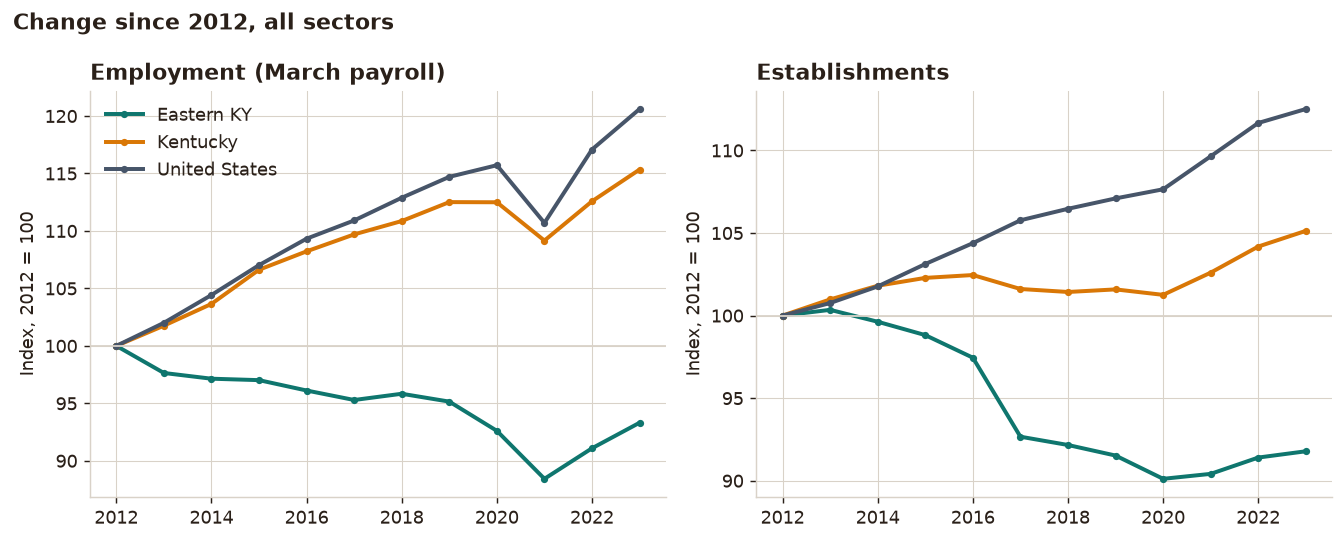

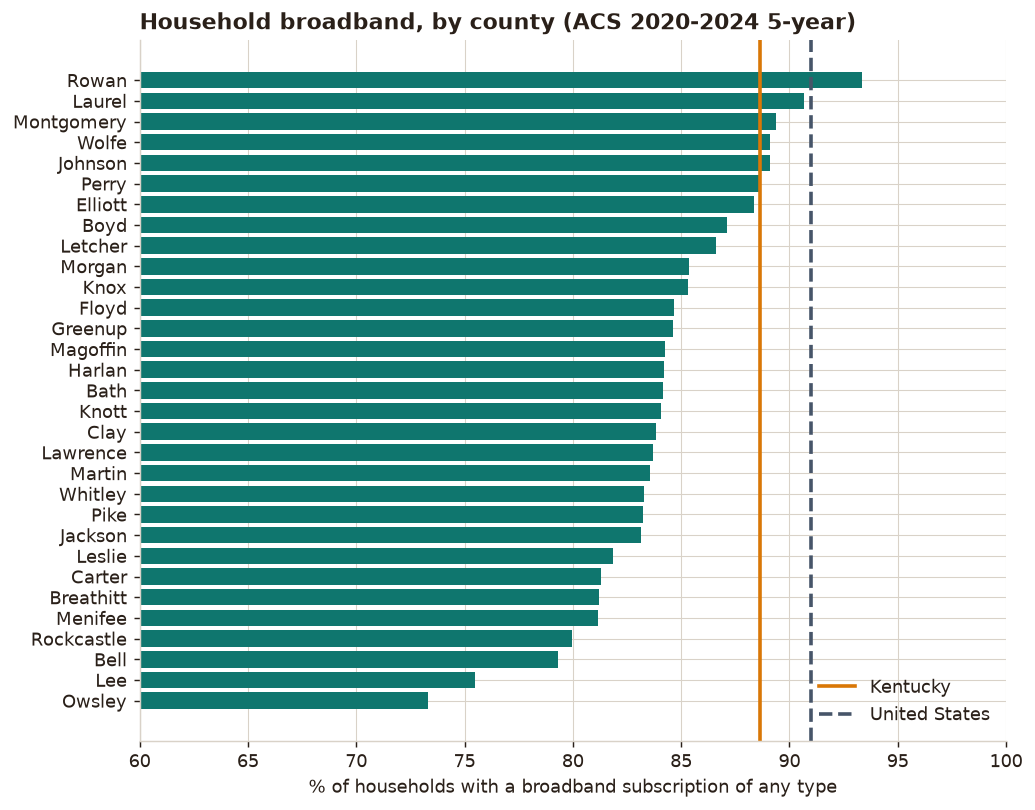

In [10]:
display(Image('../docs/charts/employment_trend.png'))
display(Image('../docs/charts/broadband.png'))